# 02 · Limpieza, Transformación y Preparación de Datos

Este notebook ejecuta paso a paso los nodos de los pipelines `data_cleaning` y `data_transformation` para documentar y justificar cada decisión. El mismo proceso se reproduce completo con:

```
kedro run --pipeline data_preprocessing
```

**Orden del pipeline:**
```
Limpieza: Drop columnas → Nulos → Valores imposibles → Duplicados → popularity = 0
Transformación: Feature Engineering → Drop IDs → One-Hot Encoding → Targets → Split → Escalado (fit en train)
No supervisado: Feature Engineering → Features de audio escaladas
```

**Problema de negocio (Caso C — Spotify):** predecir la popularidad de una canción a partir de sus características musicales y su género.
- **Regresión:** `popularity` (1–100)
- **Clasificación:** `is_hit` = 1 si `popularity >= 50` (~25% más popular)
- **No supervisado:** segmentación de canciones por sus características de audio

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nodos de los pipelines de Kedro
from evaluacion2_machine.pipelines.data_cleaning.nodes import (
    drop_columns, drop_missing_values, remove_invalid_values,
    deduplicate_tracks, filter_zero_popularity,
)
from evaluacion2_machine.pipelines.data_transformation.nodes import (
    extract_features, drop_identifier_columns, encode_categorical,
    create_targets, split_data, scale_numerical, prepare_clustering_input,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

df_raw = catalog.load("spotify_raw")
params = catalog.load("parameters")
print(f"Dataset original: {df_raw.shape}")

                    INFO     Loading data from spotify_raw (CSVDataset)...                     ]8;id=16058311;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058312;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

                    INFO     Loading data from parameters (MemoryDataset)...                   ]8;id=16058317;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058318;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

Dataset original: (114000, 21)


---
# PARTE 1 — Limpieza (`data_cleaning`)

### Paso 1 — Eliminar columnas sin información

`Unnamed: 0` es el índice que quedó guardado en el CSV.

In [3]:
df_dropped = drop_columns(df_raw, params["columns_to_drop"])
print(f"Shape: {df_raw.shape} → {df_dropped.shape}")

                    INFO     Eliminando columnas: ['Unnamed: 0']                                        ]8;id=16058325;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058326;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#12\12]8;;\

Shape: (114000, 21) → (114000, 20)


### Paso 2 — Valores nulos

Solo 1 fila tiene nulos (sin artista, álbum ni nombre). Se elimina: imputar texto no tiene sentido y su impacto es nulo.

In [4]:
print("Nulos ANTES:", int(df_dropped.isna().sum().sum()))
df_no_nulls = drop_missing_values(df_dropped)
print("Nulos DESPUÉS:", int(df_no_nulls.isna().sum().sum()))

Nulos ANTES: 3


[10/20/26 10:55:51] INFO     Filas con nulos eliminadas: 1                                              ]8;id=16058332;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058333;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#22\22]8;;\

Nulos DESPUÉS: 0


### Paso 3 — Valores imposibles

`tempo = 0`, `time_signature = 0` o `duration_ms = 0` son físicamente imposibles → errores de medición de la API.

In [5]:
cols = params["cleaning"]["invalid_zero_cols"]
total = len(df_raw)
ceros = (df_no_nulls[cols] == 0).sum().rename("cantidad").to_frame()
ceros["% del total"] = (ceros["cantidad"] / total * 100).round(2)
print(ceros.to_string())

df_valid = remove_invalid_values(df_no_nulls, cols)
eliminadas = len(df_no_nulls) - len(df_valid)
print(f"\nFilas eliminadas: {eliminadas:,} ({eliminadas / total:.2%} del total)")
print(f"Shape: {df_no_nulls.shape} → {df_valid.shape}")

                cantidad  % del total
tempo                157         0.14
time_signature       163         0.14
duration_ms            0         0.00


                    INFO     Filas con valores imposibles (0 en ['tempo', 'time_signature',             ]8;id=16058339;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058340;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#30\30]8;;\
                             'duration_ms']): 163                                                                  


Filas eliminadas: 163 (0.14% del total)
Shape: (113999, 20) → (113836, 20)


### Paso 4 — Duplicados

Dos tipos de duplicado detectados en el EDA:

1. **Mismo `track_id` en varios géneros**: la canción aparece una vez por cada género en que fue listada, con audio idéntico.
2. **Misma canción en varios álbumes** (single, álbum, recopilatorio): distinto `track_id`, mismo nombre y artista.

Si no se eliminan, la misma canción quedaría en train y en test → **data leakage**: el modelo "memoriza" en vez de generalizar. Se conserva la copia con mayor popularidad.

In [6]:
ejemplo = df_valid["track_id"].value_counts().index[0]
df_valid[df_valid["track_id"] == ejemplo][["track_name", "artists", "popularity", "track_genre"]]

,track_name,artists,popularity,track_genre
8315,Baby Blue - Remastered 2010,Badfinger,67,blues
19759,Baby Blue - Remastered 2010,Badfinger,67,country
34728,Baby Blue - Remastered 2010,Badfinger,67,folk
62226,Baby Blue - Remastered 2010,Badfinger,67,j-pop
63087,Baby Blue - Remastered 2010,Badfinger,67,j-rock
82064,Baby Blue - Remastered 2010,Badfinger,67,power-pop
84129,Baby Blue - Remastered 2010,Badfinger,67,psych-rock
99727,Baby Blue - Remastered 2010,Badfinger,67,singer-songwriter
102732,Baby Blue - Remastered 2010,Badfinger,67,songwriter


In [7]:
n_por_id = df_valid["track_id"].duplicated().sum()
df_dedup = deduplicate_tracks(df_valid, params["cleaning"]["dedupe_by_name_artist"])
n_por_nombre = len(df_valid) - len(df_dedup) - n_por_id

total = len(df_raw)
dups = pd.Series({
    "Duplicados por track_id": n_por_id,
    "Duplicados por nombre + artista": n_por_nombre,
    "Total eliminados": n_por_id + n_por_nombre,
}, name="cantidad").to_frame()
dups["% del total"] = (dups["cantidad"] / total * 100).round(2)
print(dups.to_string())

print(f"\nShape: {df_valid.shape} → {df_dedup.shape}")
print("track_id repetidos después:", df_dedup["track_id"].duplicated().sum())

                    INFO     Duplicados por track_id eliminados: 24258                                  ]8;id=16058346;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058347;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#43\43]8;;\

                    INFO     Duplicados por nombre+artista eliminados: 8385                             ]8;id=16058353;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058354;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#50\50]8;;\

                                 cantidad  % del total
Duplicados por track_id             24258        21.28
Duplicados por nombre + artista      8385         7.36
Total eliminados                    32643        28.63

Shape: (113836, 20) → (81193, 20)


track_id repetidos después: 0


### Paso 5 — Canciones con `popularity = 0`

Spotify calcula la popularidad **por versión** (`track_id`). En el EDA (sección 8.1) se vio que muchos ceros son éxitos mundiales —por ejemplo *Con Calma* o *MIA*— tomados de recopilatorios y playlists, cuyas copias no acumulan reproducciones propias. El pico en 0 no representa "impopularidad" sino un **artefacto de recopilación**, y mantenerlo sesgaría el target de regresión.

**Limitación:** el modelo no se evalúa con canciones sin datos de reproducción, y en géneros latinos persiste un sesgo residual (valores de 1–2 con el mismo origen).

                    INFO     Canciones con popularity = 0 eliminadas: 4754                              ]8;id=16058360;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py\nodes.py]8;;\:]8;id=16058361;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_cleaning\nodes.py#65\65]8;;\

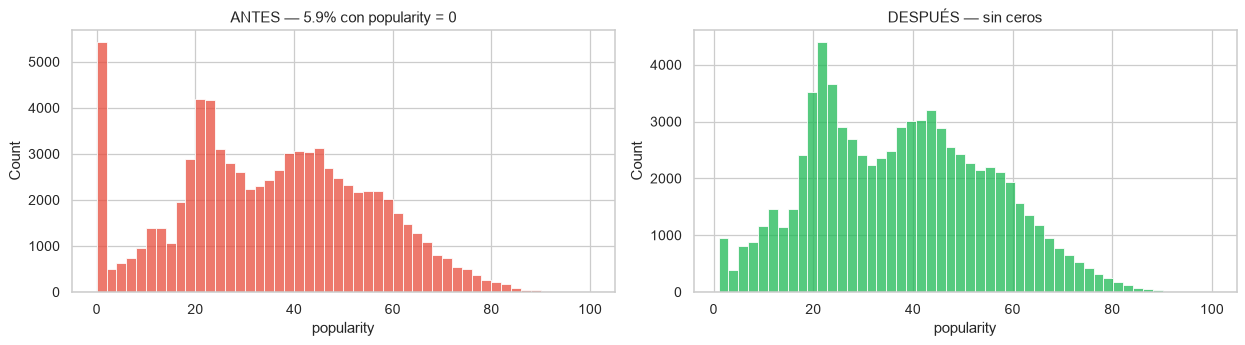

In [8]:
df_clean = filter_zero_popularity(df_dedup, params["cleaning"]["drop_zero_popularity"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_dedup["popularity"], bins=50, ax=axes[0], color="#E74C3C")
axes[0].set_title(f"ANTES — {(df_dedup['popularity'] == 0).mean():.1%} con popularity = 0")
sns.histplot(df_clean["popularity"], bins=50, ax=axes[1], color="#1DB954")
axes[1].set_title("DESPUÉS — sin ceros")
plt.tight_layout()
plt.show()

### Resumen de la limpieza

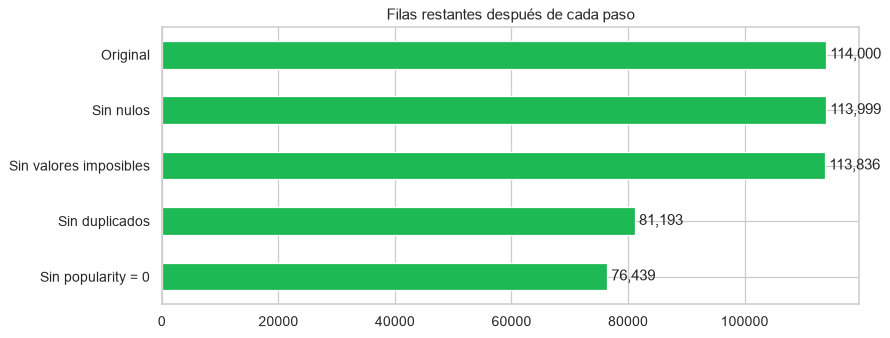

Se conserva el 67.1% de las filas originales


In [9]:
pasos = pd.Series({
    "Original": len(df_raw),
    "Sin nulos": len(df_no_nulls),
    "Sin valores imposibles": len(df_valid),
    "Sin duplicados": len(df_dedup),
    "Sin popularity = 0": len(df_clean),
})
ax = pasos.plot.barh(figsize=(10, 4), color="#1DB954")
ax.invert_yaxis()
for i, v in enumerate(pasos):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Filas restantes después de cada paso")
plt.show()
print(f"Se conserva el {len(df_clean) / len(df_raw):.1%} de las filas originales")

---
# PARTE 2 — Transformación (`data_transformation`)

### Paso 6 — Feature Engineering

- `duration_min` = `duration_ms` / 60.000 (más interpretable)
- `n_artists`: número de artistas (el campo `artists` los separa con `;`)
- `is_collab`: 1 si es colaboración
- `explicit` pasa de bool a int (sklearn no acepta bool)

In [10]:
df_features = extract_features(df_clean)
print(f"Shape: {df_clean.shape} → {df_features.shape}")
df_features[["duration_min", "n_artists", "is_collab", "explicit"]].describe().round(2)

                    INFO     Features extraídas: duration_min, n_artists, is_collab                     ]8;id=16058368;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058369;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#21\21]8;;\

Shape: (76439, 20) → (76439, 22)


,duration_min,n_artists,is_collab,explicit
count,76439.00,76439.00,76439.00,76439.00
mean,3.86,1.37,0.25,0.09
std,1.92,0.88,0.43,0.28
min,0.40,1.00,0.00,0.00
25%,2.90,1.00,0.00,0.00
50%,3.60,1.00,0.00,0.00
75%,4.47,1.00,0.00,0.00
max,87.29,38.00,1.00,1.00


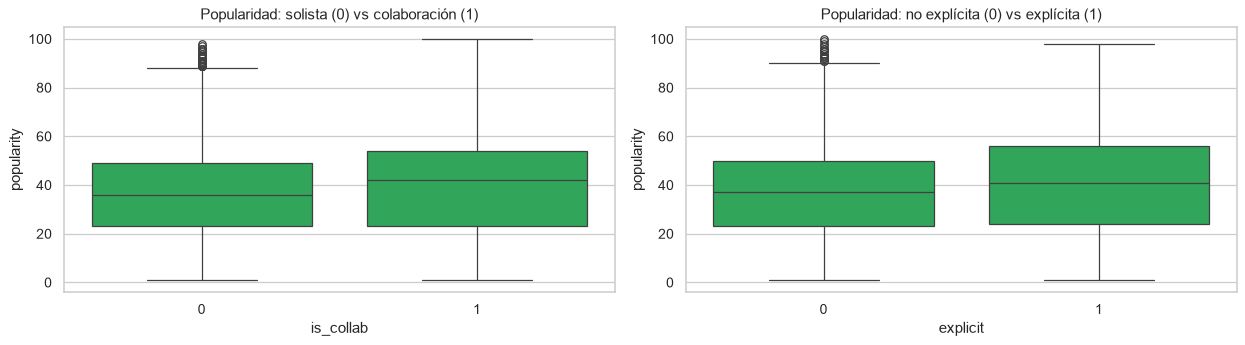

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df_features, x="is_collab", y="popularity", ax=axes[0], color="#1DB954")
axes[0].set_title("Popularidad: solista (0) vs colaboración (1)")
sns.boxplot(data=df_features, x="explicit", y="popularity", ax=axes[1], color="#1DB954")
axes[1].set_title("Popularidad: no explícita (0) vs explícita (1)")
plt.tight_layout()
plt.show()

### Paso 7 — Eliminar identificadores

`track_id`, `artists`, `album_name` y `track_name` son texto libre con decenas de miles de valores únicos: no generalizan a canciones nuevas.

In [12]:
df_no_ids = drop_identifier_columns(df_features, params["id_columns"])
print(f"Shape: {df_features.shape} → {df_no_ids.shape}")

[10/20/26 10:55:52] INFO     Eliminando identificadores: ['track_id', 'artists', 'album_name',          ]8;id=16058375;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058376;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#30\30]8;;\
                             'track_name']                                                                         

Shape: (76439, 22) → (76439, 18)


### Paso 8 — One-Hot Encoding

`track_genre` (114), `key` (12) y `time_signature` son **nominales**: un orden numérico (ej. key 0 < 11) no tiene sentido musical, por eso se usa One-Hot en vez de Label Encoding. `mode` y `explicit` ya son binarias.

In [13]:
df_encoded = encode_categorical(df_no_ids, params["categorical_cols_ohe"])
print(f"Columnas ANTES: {df_no_ids.shape[1]} → DESPUÉS: {df_encoded.shape[1]}")
for prefijo in params["categorical_cols_ohe"]:
    n = sum(c.startswith(prefijo + "_") for c in df_encoded.columns)
    print(f"  {prefijo}: {n} columnas")

                    INFO     One-Hot Encoding aplicado a ['track_genre', 'key', 'time_signature'] —     ]8;id=16058382;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058383;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#46\46]8;;\
                             columnas totales: 145                                                                 

Columnas ANTES: 18 → DESPUÉS: 145
  track_genre: 114 columnas
  key: 12 columnas
  time_signature: 4 columnas


### Paso 9 — Creación de targets

- **Regresión:** `popularity` sin transformar (1–100), así MAE/RMSE se interpretan en puntos de popularidad.
- **Clasificación:** `is_hit` = 1 si `popularity >= 50` (≈ percentil 75 del dataset limpio).

                    INFO     Target is_hit (popularity >= 50) — tasa positiva: 0.266                    ]8;id=16058389;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058390;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#59\59]8;;\

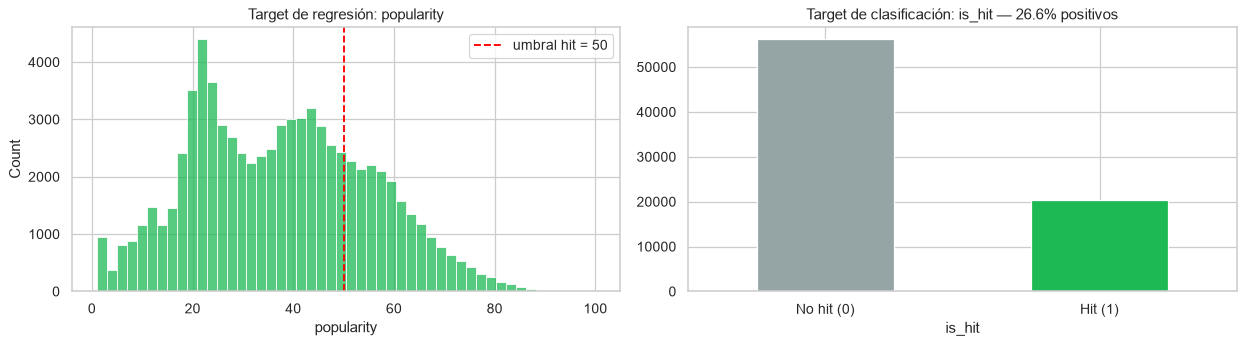

In [14]:
df_model = create_targets(df_encoded, params["hit_threshold"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_model["popularity"], bins=50, ax=axes[0], color="#1DB954")
axes[0].axvline(params["hit_threshold"], color="red", ls="--", label=f"umbral hit = {params['hit_threshold']}")
axes[0].legend()
axes[0].set_title("Target de regresión: popularity")
df_model["is_hit"].value_counts().sort_index().plot.bar(ax=axes[1], color=["#95A5A6", "#1DB954"])
axes[1].set_xticklabels(["No hit (0)", "Hit (1)"], rotation=0)
axes[1].set_title(f"Target de clasificación: is_hit — {df_model['is_hit'].mean():.1%} positivos")
plt.tight_layout()
plt.show()

Con ~27% de positivos el dataset está **desbalanceado**: un modelo que siempre prediga "no hit" tendría 73% de Accuracy. Por eso la evaluación de clasificadores debe usar **F1, Recall y ROC-AUC**.

### Paso 10 — Split train/test (80/20 estratificado)

Un único split estratificado por `is_hit` para ambas tareas: clasificación y regresión se evalúan sobre las mismas canciones.

In [15]:
(X_train_unscaled, X_test_unscaled,
 y_train_clf, y_test_clf,
 y_train_reg, y_test_reg) = split_data(df_model, params["modeling"])

resumen = pd.DataFrame({
    "filas": [len(X_train_unscaled), len(X_test_unscaled)],
    "% is_hit": [y_train_clf["is_hit"].mean(), y_test_clf["is_hit"].mean()],
    "popularity media": [y_train_reg["popularity"].mean(), y_test_reg["popularity"].mean()],
}, index=["train", "test"]).round(3)
resumen

[10/20/26 10:55:53] INFO     Split: train=61151, test=15288 | is_hit train=0.266 test=0.266             ]8;id=16058396;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058397;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#84\84]8;;\

,filas,% is_hit,popularity media
train,61151,0.266,37.439
test,15288,0.266,37.434


### Paso 11 — Escalado (StandardScaler, fit solo en train)

El escalador se ajusta **solo con train** y se aplica a test: si se ajustara con todo el dataset, la media y desviación de test se filtrarían al entrenamiento (data leakage). Las columnas One-Hot y binarias no se escalan para mantener su significado 0/1.

StandardScaler es necesario para KNN, SVM y modelos lineales; a los árboles no les afecta.

In [16]:
X_train, X_test, scaler = scale_numerical(
    X_train_unscaled, X_test_unscaled, params["numerical_cols_scale"], params["scaler_type"]
)
cols = params["numerical_cols_scale"]
pd.DataFrame({
    "media train": X_train[cols].mean(), "std train": X_train[cols].std(),
    "media test": X_test[cols].mean(), "std test": X_test[cols].std(),
}).round(3)

                    INFO     Escalado 'standard' (fit en train) aplicado a: ['danceability', 'energy', ]8;id=16058403;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058404;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#125\125]8;;\
                             'loudness', 'speechiness', 'acousticness', 'instrumentalness',                        
                             'liveness', 'valence', 'tempo', 'duration_min', 'n_artists']                          

,media train,std train,media test,std test
danceability,-0.0,1.0,0.006,0.991
energy,-0.0,1.0,-0.005,0.991
loudness,-0.0,1.0,-0.005,0.996
speechiness,-0.0,1.0,-0.003,0.992
acousticness,0.0,1.0,0.004,0.996
instrumentalness,-0.0,1.0,-0.001,0.993
liveness,-0.0,1.0,-0.001,1.001
valence,0.0,1.0,0.003,0.996
tempo,-0.0,1.0,0.003,1.009
duration_min,0.0,1.0,-0.003,0.963


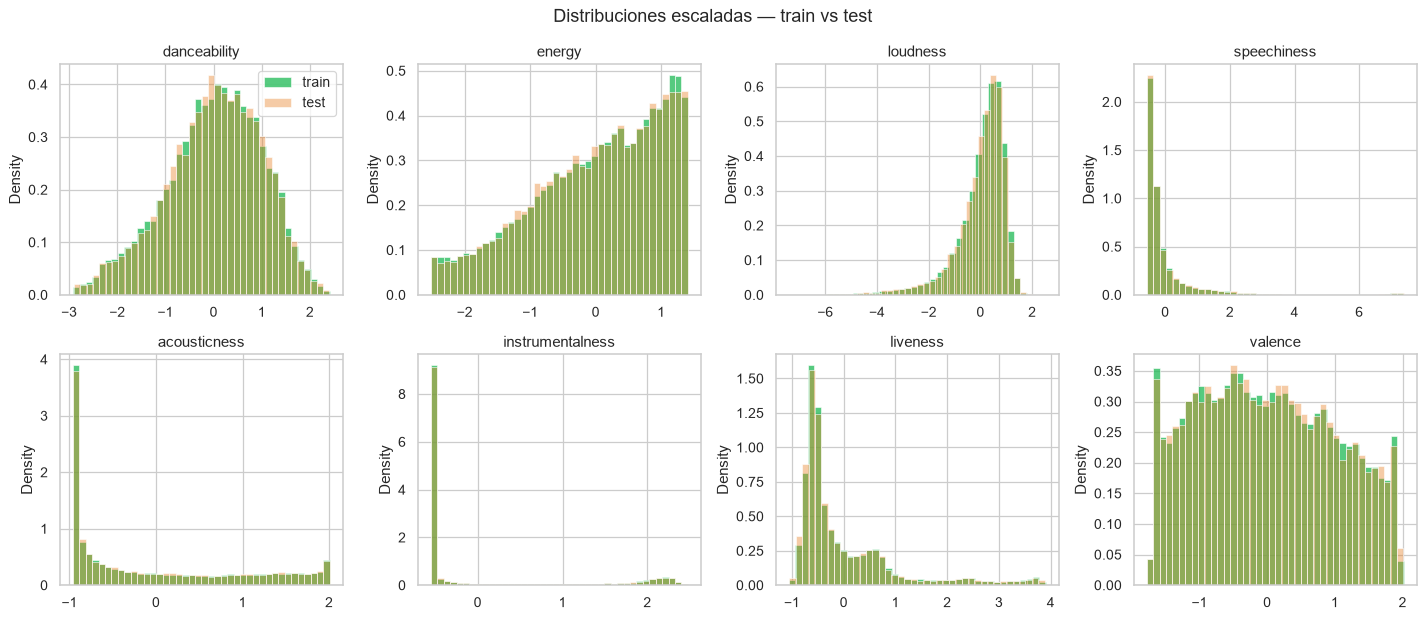

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols[:8]):
    sns.histplot(X_train[col], bins=40, ax=ax, color="#1DB954", stat="density", label="train")
    sns.histplot(X_test[col], bins=40, ax=ax, color="#E67E22", stat="density", alpha=0.4, label="test")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[0].legend()
plt.suptitle("Distribuciones escaladas — train vs test")
plt.tight_layout()
plt.show()

Train y test tienen distribuciones equivalentes: el split es representativo.

---
# PARTE 3 — Input del modelo no supervisado

Para el clustering se usan **solo las características de audio** (sin género ni popularidad): la idea es descubrir segmentos musicales a partir del sonido y luego contrastarlos con el género y la popularidad. Al no haber train/test, el escalado se ajusta con todo el dataset; es obligatorio porque K-Means y DBSCAN usan distancias euclídeas.

In [18]:
X_cluster = prepare_clustering_input(df_features, params["clustering_features"], params["scaler_type"])
print(f"Shape: {X_cluster.shape}")
X_cluster.describe().T[["mean", "std", "min", "max"]].round(2)

[10/20/26 10:55:54] INFO     Input de clustering: 76439 filas x 10 features                            ]8;id=16058410;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py\nodes.py]8;;\:]8;id=16058411;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\src\evaluacion2_machine\pipelines\data_transformation\nodes.py#138\138]8;;\

Shape: (76439, 10)


,mean,std,min,max
danceability,-0.0,1.0,-2.93,2.42
energy,-0.0,1.0,-2.52,1.41
loudness,-0.0,1.0,-7.42,2.53
speechiness,-0.0,1.0,-0.57,7.39
acousticness,0.0,1.0,-0.96,2.01
instrumentalness,0.0,1.0,-0.55,2.48
liveness,0.0,1.0,-1.06,3.90
valence,0.0,1.0,-1.78,2.02
tempo,0.0,1.0,-3.11,4.07
duration_min,0.0,1.0,-1.80,43.41


---
# Verificación contra los datos generados por Kedro

Se comprueba que lo calculado en este notebook es idéntico a lo que guarda `kedro run` en el catálogo.

In [19]:
for nombre, local in [("spotify_clean", df_clean), ("X_train", X_train), ("X_test", X_test),
                      ("y_train_clf", y_train_clf), ("y_train_reg", y_train_reg),
                      ("spotify_clustering_input", X_cluster)]:
    guardado = catalog.load(nombre)
    iguales = np.allclose(guardado.select_dtypes("number").values,
                          local.reset_index(drop=True).select_dtypes("number").values)
    print(f"{nombre:26s} {str(guardado.shape):14s} idéntico: {iguales}")

                    INFO     Loading data from spotify_clean (CSVDataset)...                   ]8;id=16058416;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058417;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

spotify_clean              (76439, 20)    idéntico: True


[10/20/26 10:55:55] INFO     Loading data from X_train (CSVDataset)...                         ]8;id=16058422;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058423;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

X_train                    (61151, 144)   idéntico: True


[10/20/26 10:55:56] INFO     Loading data from X_test (CSVDataset)...                          ]8;id=16058428;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058429;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

...

y_train_clf                (61151, 1)     idéntico: True


                    INFO     Loading data from y_train_reg (CSVDataset)...                     ]8;id=16058440;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058441;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

y_train_reg                (61151, 1)     idéntico: True


                    INFO     Loading data from spotify_clustering_input (CSVDataset)...        ]8;id=16058446;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=16058447;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

spotify_clustering_input   (76439, 10)    idéntico: True


---
# Resumen — datos listos para modelar

| Dataset (catálogo) | Uso |
|---|---|
| `X_train`, `X_test` | Features escaladas (11 numéricas + binarias + One-Hot de género, key y compás) |
| `y_train_clf`, `y_test_clf` | Target de clasificación `is_hit` |
| `y_train_reg`, `y_test_reg` | Target de regresión `popularity` |
| `spotify_clustering_input` | 10 features de audio escaladas para K-Means / DBSCAN |
| `scaler` | StandardScaler ajustado en train (`data/06_models/scaler.pkl`) |

**Decisiones clave:**
1. Deduplicación por `track_id` y por nombre+artista para evitar data leakage entre train y test.
2. Exclusión de `popularity = 0` por representar ausencia de datos.
3. One-Hot para variables nominales (género, tonalidad, compás).
4. Escalado ajustado solo en train.
5. Split estratificado por `is_hit` por el desbalance de clases (~27% positivos).

**Próximo paso:** entrenamiento y comparación de modelos supervisados y no supervisados.